# Point Estimation

Companion notebook for [notes/estimation/point_estimation.md](../../notes/estimation/point_estimation.md).

A **point estimator** is a rule that turns a sample into a single number intended to approximate an unknown parameter. Because the estimator is a random variable, its quality is described by its **bias**, **variance**, and **mean-squared error** over repeated samples. In this notebook we use simulation (with a fixed seed) to see these properties directly, and then compare the method of moments with maximum likelihood.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(123)

## 1. Bias, variance, and MSE of $1/\bar X$

For exponential data with rate $\lambda$, both the method of moments and maximum likelihood give $\hat\lambda=1/\bar X$. Theory says $E[1/\bar X]=\frac{n}{n-1}\lambda$, so the estimator is biased upward by $\lambda/(n-1)$. We draw 10,000 samples of size 80 and examine the sampling distribution.

In [2]:
true_rate = 0.4
n = 80
reps = 10_000

samples = rng.exponential(scale=1 / true_rate, size=(reps, n))
estimates = 1.0 / samples.mean(axis=1)

bias = estimates.mean() - true_rate
variance = estimates.var()
mse = np.mean((estimates - true_rate) ** 2)

print(f"Mean of estimates: {estimates.mean():.4f}")
print(f"Monte Carlo bias:  {bias:.4f}   (theory: {true_rate / (n - 1):.4f})")
print(f"Variance:          {variance:.5f}")
print(f"MSE:               {mse:.5f}")
print(f"bias^2 + variance: {bias**2 + variance:.5f}")

Mean of estimates: 0.4056
Monte Carlo bias:  0.0056   (theory: 0.0051)
Variance:          0.00212
MSE:               0.00215
bias^2 + variance: 0.00215


The MSE equals variance plus squared bias, as the decomposition promises. The bias is small relative to the standard error, so it hardly matters here, but it is not zero.

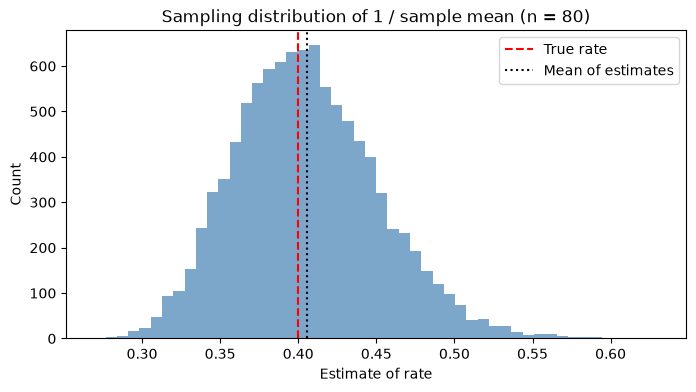

In [3]:
plt.figure(figsize=(8, 4))
plt.hist(estimates, bins=50, alpha=0.7, color="steelblue")
plt.axvline(true_rate, color="red", linestyle="--", label="True rate")
plt.axvline(estimates.mean(), color="black", linestyle=":", label="Mean of estimates")
plt.title("Sampling distribution of 1 / sample mean (n = 80)")
plt.xlabel("Estimate of rate")
plt.ylabel("Count")
plt.legend()
plt.show()

## 2. Correcting the bias

The estimator $\frac{n-1}{n\bar X}$ is unbiased. Correcting bias can slightly *increase* variance, so we compare MSE as well.

In [4]:
corrected = (n - 1) / (n * samples.mean(axis=1))

for name, est in [("1/xbar", estimates), ("(n-1)/(n xbar)", corrected)]:
    print(f"{name:15s} bias={est.mean() - true_rate:+.4f}  "
          f"var={est.var():.5f}  MSE={np.mean((est - true_rate) ** 2):.5f}")

1/xbar          bias=+0.0056  var=0.00212  MSE=0.00215
(n-1)/(n xbar)  bias=+0.0005  var=0.00207  MSE=0.00207


## 3. Variance estimators: divisor $n$ versus $n-1$

For normal data the MLE of $\sigma^2$ divides by $n$ and is biased low by the factor $(n-1)/n$; the sample variance $S^2$ divides by $n-1$ and is unbiased. With small $n$ the difference is visible.

In [5]:
sigma2 = 4.0
n_small = 10
x = rng.normal(0, np.sqrt(sigma2), size=(20_000, n_small))

mle_var = x.var(axis=1, ddof=0)
unbiased_var = x.var(axis=1, ddof=1)

for name, v in [("MLE (divide by n)", mle_var), ("S^2 (divide by n-1)", unbiased_var)]:
    print(f"{name:20s} mean={v.mean():.3f}  bias={v.mean() - sigma2:+.3f}  "
          f"MSE={np.mean((v - sigma2) ** 2):.3f}")
print(f"Theory: E[MLE] = {(n_small - 1) / n_small * sigma2:.2f}, "
      f"MSE(S^2) = {2 * sigma2**2 / (n_small - 1):.3f}")

MLE (divide by n)    mean=3.602  bias=-0.398  MSE=3.070
S^2 (divide by n-1)  mean=4.003  bias=+0.003  MSE=3.595
Theory: E[MLE] = 3.60, MSE(S^2) = 3.556


The biased MLE has *smaller* MSE here (about 3.04 versus 3.56 in theory): a little bias buys a larger reduction in variance. This is the bias-variance trade-off at work.

## 4. Consistency

A consistent estimator concentrates around the true value as $n$ grows. We track the spread of $\hat\lambda=1/\bar X$ for increasing sample sizes.

n=    5  mean=0.5077  sd=0.3016
n=   10  mean=0.4439  sd=0.1542
n=   20  mean=0.4223  sd=0.1026
n=   50  mean=0.4091  sd=0.0594
n=  100  mean=0.4049  sd=0.0406
n=  500  mean=0.4006  sd=0.0179
n= 2000  mean=0.4003  sd=0.0089


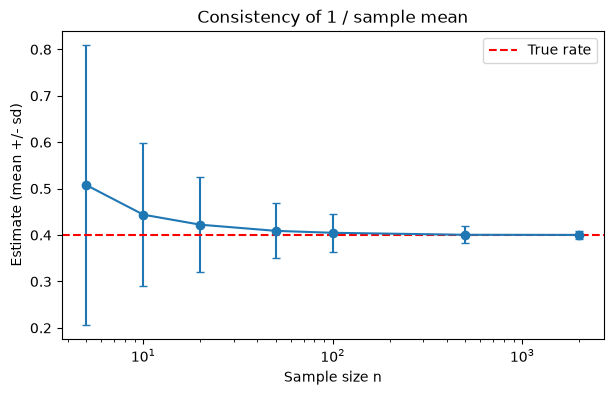

In [6]:
sizes = [5, 10, 20, 50, 100, 500, 2000]
rows = []
for m in sizes:
    est = 1.0 / rng.exponential(1 / true_rate, size=(2000, m)).mean(axis=1)
    rows.append((m, est.mean(), est.std()))
    print(f"n={m:5d}  mean={est.mean():.4f}  sd={est.std():.4f}")

plt.figure(figsize=(7, 4))
plt.errorbar([r[0] for r in rows], [r[1] for r in rows], yerr=[r[2] for r in rows], fmt="o-", capsize=3)
plt.axhline(true_rate, color="red", linestyle="--", label="True rate")
plt.xscale("log")
plt.xlabel("Sample size n")
plt.ylabel("Estimate (mean +/- sd)")
plt.title("Consistency of 1 / sample mean")
plt.legend()
plt.show()

Both the bias and the standard deviation shrink as $n$ grows, which is exactly what consistency means. A point estimate alone, however, says nothing about this spread; that is the job of confidence intervals, the next topic.